In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Select your skincare reviews CSV",
    filetypes=[("CSV files", "*.csv")]
)

root.destroy()

if file_path:
    reviews = pd.read_csv(file_path, low_memory=False)
    print("Dataset loaded successfully!")
    print("Dataset shape:", reviews.shape)
    display(reviews.head())
else:
    print("No file selected. Run this cell again.")

Dataset loaded successfully!
Dataset shape: (206725, 19)


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,2190293206,2,0.0,NaN,0,0,0,2023-03-19,Used to swear by this product but hate the sme...,NaN,lightMedium,brown,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
1,1,9113341005,5,1.0,NaN,0,0,0,2023-03-18,I’ve only been using this for a week and my sk...,More tolerable than The Ordinary,deep,brown,normal,black,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
2,2,23866342710,1,0.0,1.000000,13,0,13,2023-03-12,"Why, why, why would you change the formula?!!!...",New formula is awful very sad,fairLight,blue,combination,blonde,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
3,3,1328806527,1,0.0,0.941176,17,1,16,2023-03-12,I have used this product for years and it has ...,Recently reformulated and the new formula is A...,light,brown,combination,gray,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
4,4,31262847082,5,1.0,1.000000,1,0,1,2023-03-09,Great product for anti-aging Also great for da...,Must have product in my nighttime skincare rou...,lightMedium,hazel,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99


In [4]:
print("File selected:", file_path)
print("Dataset loaded:", "reviews" in globals())

if "reviews" in globals():
    print("Dataset shape:", reviews.shape)
    display(reviews.head())

File selected: C:/Users/ARYAN KATAKDHOND/Downloads/archive/reviews_250-500.csv
Dataset loaded: True
Dataset shape: (206725, 19)


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,2190293206,2,0.0,NaN,0,0,0,2023-03-19,Used to swear by this product but hate the sme...,NaN,lightMedium,brown,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
1,1,9113341005,5,1.0,NaN,0,0,0,2023-03-18,I’ve only been using this for a week and my sk...,More tolerable than The Ordinary,deep,brown,normal,black,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
2,2,23866342710,1,0.0,1.000000,13,0,13,2023-03-12,"Why, why, why would you change the formula?!!!...",New formula is awful very sad,fairLight,blue,combination,blonde,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
3,3,1328806527,1,0.0,0.941176,17,1,16,2023-03-12,I have used this product for years and it has ...,Recently reformulated and the new formula is A...,light,brown,combination,gray,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
4,4,31262847082,5,1.0,1.000000,1,0,1,2023-03-09,Great product for anti-aging Also great for da...,Must have product in my nighttime skincare rou...,lightMedium,hazel,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99


In [5]:
# WEEK 2: DATA QUALITY AUDIT

# 1. Check column names
print("COLUMN NAMES")
print(reviews.columns.tolist())

# 2. Check data types
print("\nDATA TYPES")
display(reviews.dtypes.to_frame("Data Type"))

# 3. Check missing values
print("\nMISSING VALUES")
quality_report = pd.DataFrame({
    "Missing Count": reviews.isnull().sum(),
    "Missing Percentage": (
        reviews.isnull().mean() * 100
    ).round(2)
})

display(
    quality_report.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

# 4. Check duplicate rows
print("\nEXACT DUPLICATE ROWS")
print(reviews.duplicated().sum())

# 5. Check rating distribution
print("\nRATING DISTRIBUTION")
display(
    reviews["rating"].value_counts(dropna=False).sort_index()
)

COLUMN NAMES
['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

DATA TYPES


,Data Type
Unnamed: 0,int64
author_id,str
rating,int64
is_recommended,float64
helpfulness,float64
total_feedback_count,int64
total_neg_feedback_count,int64
total_pos_feedback_count,int64
submission_time,str
review_text,str



MISSING VALUES


,Missing Count,Missing Percentage
helpfulness,107874,52.18
review_title,59728,28.89
hair_color,36544,17.68
eye_color,33774,16.34
skin_tone,26799,12.96
is_recommended,25986,12.57
skin_type,16749,8.10
review_text,172,0.08
rating,0,0.00
Unnamed: 0,0,0.00



EXACT DUPLICATE ROWS
0

RATING DISTRIBUTION


rating
1     11602
2     10247
3     17090
4     41504
5    126282
Name: count, dtype: int64

In [6]:
# Create a working copy
clean_reviews = reviews.copy()

# Remove rows without review text
clean_reviews["review_text"] = (
    clean_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean_reviews = clean_reviews[
    clean_reviews["review_text"] != ""
].copy()

# Check the result
print("Original records:", len(reviews))
print("Records after removing blank reviews:", len(clean_reviews))
print("Records removed:", len(reviews) - len(clean_reviews))

print("\nRemaining missing review text:")
print(clean_reviews["review_text"].isna().sum())

display(clean_reviews[["rating", "review_title", "review_text"]].head())

Original records: 206725
Records after removing blank reviews: 206553
Records removed: 172

Remaining missing review text:
0


,rating,review_title,review_text
0,2,NaN,Used to swear by this product but hate the sme...
1,5,More tolerable than The Ordinary,I’ve only been using this for a week and my sk...
2,1,New formula is awful very sad,"Why, why, why would you change the formula?!!!..."
3,1,Recently reformulated and the new formula is A...,I have used this product for years and it has ...
4,5,Must have product in my nighttime skincare rou...,Great product for anti-aging Also great for da...


In [7]:
# Calculate the length of each review
clean_reviews["review_length"] = (
    clean_reviews["review_text"].str.len()
)

# Display summary statistics
print("REVIEW LENGTH SUMMARY")
display(clean_reviews["review_length"].describe())

# Find the shortest and longest reviews
print("Shortest review length:",
      clean_reviews["review_length"].min())

print("Longest review length:",
      clean_reviews["review_length"].max())

REVIEW LENGTH SUMMARY


count    206553.000000
mean        329.347993
std         232.598384
min          17.000000
25%         182.000000
50%         272.000000
75%         411.000000
max        6448.000000
Name: review_length, dtype: float64

Shortest review length: 17
Longest review length: 6448


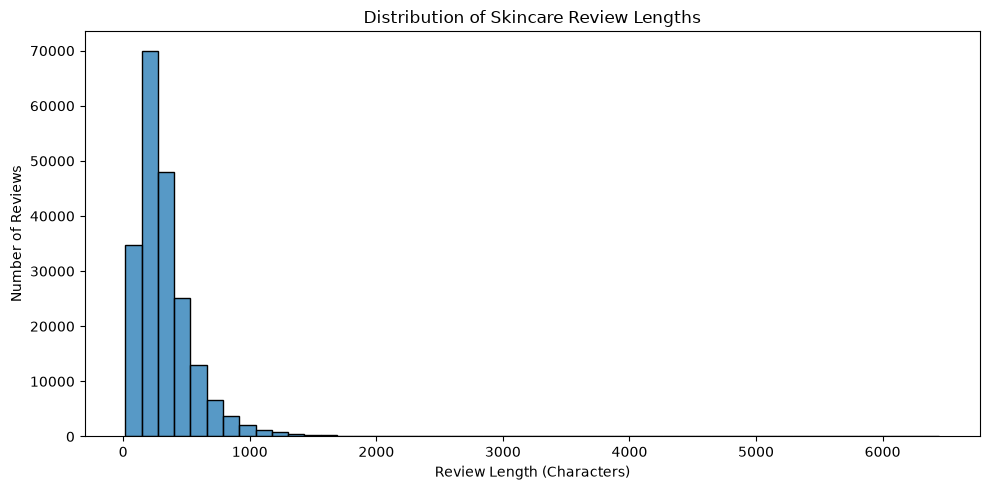

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean_reviews,
    x="review_length",
    bins=50
)

plt.title("Distribution of Skincare Review Lengths")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

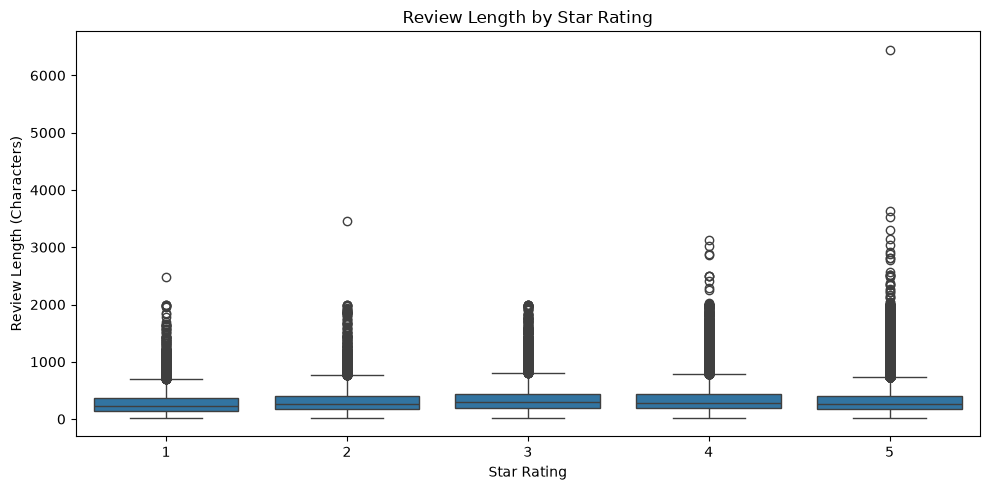

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=clean_reviews,
    x="rating",
    y="review_length"
)

plt.title("Review Length by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Review Length (Characters)")
plt.tight_layout()
plt.show()

In [11]:
# Compare review lengths by star rating

length_summary = (
    clean_reviews
    .groupby("rating")["review_length"]
    .agg(
        Review_Count="count",
        Average_Length="mean",
        Median_Length="median",
        P90_Length=lambda x: x.quantile(0.90)
    )
    .round(2)
)

display(length_summary)

,Review_Count,Average_Length,Median_Length,P90_Length
rating,,,,
1,11583,285.83,229.0,549.0
2,10232,320.38,261.0,593.9
3,17084,350.89,292.0,645.7
4,41488,347.30,289.0,626.0
5,126166,325.25,268.0,595.0


In [12]:
# Brand-level rating analysis

brand_summary = (
    clean_reviews
    .dropna(subset=["brand_name", "rating"])
    .groupby("brand_name")
    .agg(
        Review_Count=("rating", "count"),
        Average_Rating=("rating", "mean")
    )
)

# Keep brands with at least 100 reviews
brand_summary = brand_summary[
    brand_summary["Review_Count"] >= 100
]

brand_summary["Average_Rating"] = (
    brand_summary["Average_Rating"].round(2)
)

# Top 10 brands by average rating
top_brands = brand_summary.sort_values(
    "Average_Rating", ascending=False
).head(10)

display(top_brands)

,Review_Count,Average_Rating
brand_name,,
Benefit Cosmetics,2125,4.67
St. Tropez,1053,4.67
Sulwhasoo,2913,4.58
Dermalogica,2994,4.53
Shiseido,4283,4.52
Alpha-H,910,4.51
Origins,3039,4.50
Dior,3035,4.50
Augustinus Bader,661,4.48


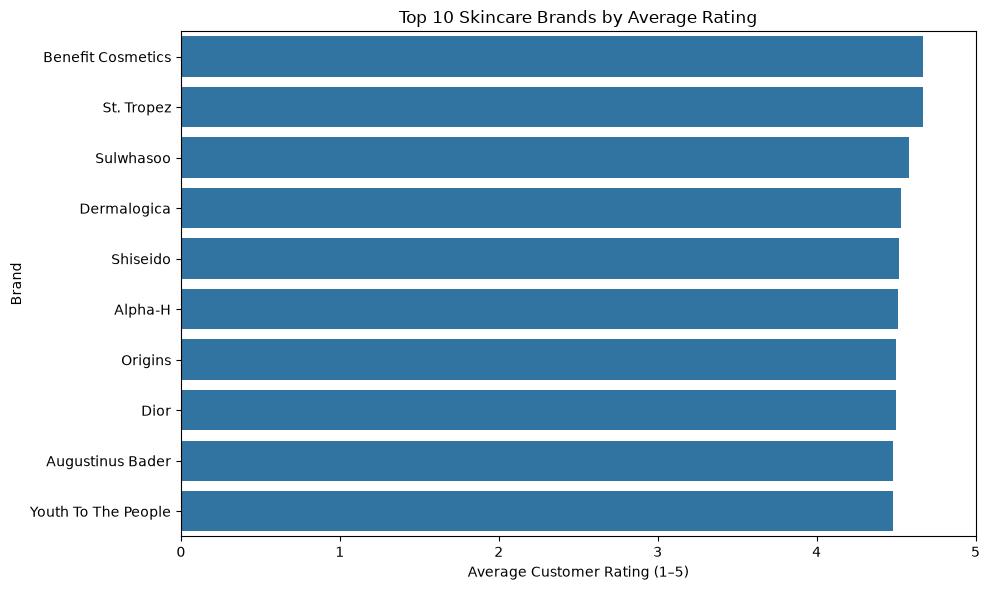

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_brands.reset_index(),
    x="Average_Rating",
    y="brand_name"
)

plt.title("Top 10 Skincare Brands by Average Rating")
plt.xlabel("Average Customer Rating (1–5)")
plt.ylabel("Brand")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

In [14]:
# Calculate low-rating percentage for each brand

brand_low_ratings = (
    clean_reviews
    .dropna(subset=["brand_name", "rating"])
    .assign(
        low_rating=lambda df: df["rating"].isin([1, 2])
    )
    .groupby("brand_name")
    .agg(
        Review_Count=("rating", "count"),
        Low_Rating_Count=("low_rating", "sum"),
        Average_Rating=("rating", "mean")
    )
)

# Keep brands with at least 100 reviews
brand_low_ratings = brand_low_ratings[
    brand_low_ratings["Review_Count"] >= 100
].copy()

brand_low_ratings["Low_Rating_Percentage"] = (
    100 * brand_low_ratings["Low_Rating_Count"]
    / brand_low_ratings["Review_Count"]
).round(2)

# Show the 10 brands with the highest low-rating percentage
bottom_brands = brand_low_ratings.sort_values(
    "Low_Rating_Percentage", ascending=False
).head(10)

display(bottom_brands)

,Review_Count,Low_Rating_Count,Average_Rating,Low_Rating_Percentage
brand_name,,,,
SEPHORA COLLECTION,611,395,2.279869,64.65
Topicals,1838,492,3.660501,26.77
Isle of Paradise,1072,247,3.710821,23.04
Algenist,644,148,3.875776,22.98
ILIA,635,129,3.656693,20.31
COOLA,1421,277,3.933849,19.49
GLO Science,779,146,3.998716,18.74
Supergoop!,2764,506,4.005065,18.31
JLo Beauty,604,102,3.942053,16.89


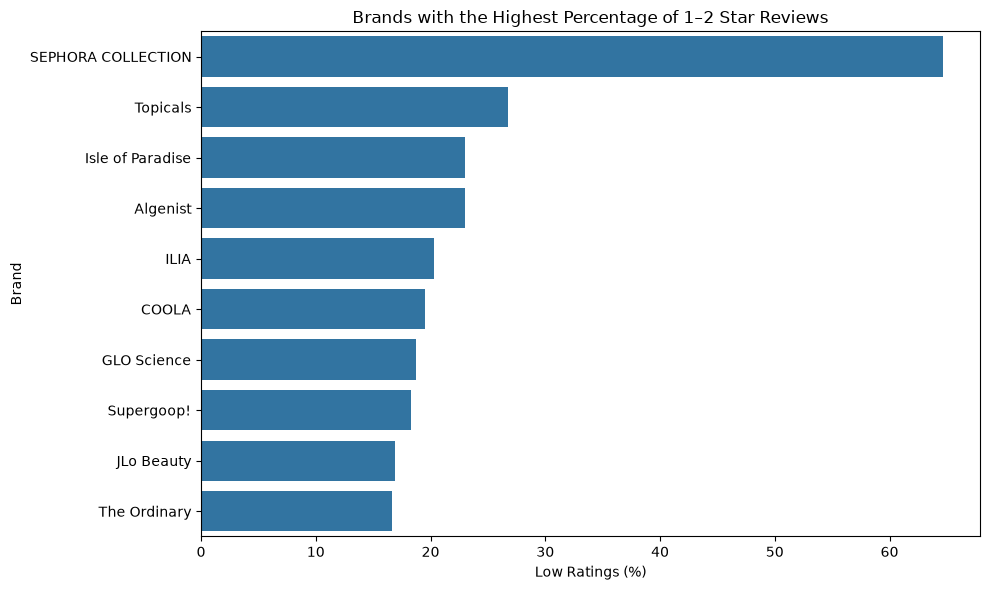

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=bottom_brands.reset_index(),
    x="Low_Rating_Percentage",
    y="brand_name"
)

plt.title("Brands with the Highest Percentage of 1–2 Star Reviews")
plt.xlabel("Low Ratings (%)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [17]:

# Week 2: Key findings summary

print("WEEK 2 DATA ANALYSIS SUMMARY")
print("-" * 40)

print("Original dataset rows:", len(reviews))
print("Rows after removing blank reviews:", len(clean_reviews))
print("Rows removed:", len(reviews) - len(clean_reviews))

print("\nAverage review length by rating:")
display(length_summary)

print("\nTop 5 brands by average rating:")
display(top_brands.head())

print("\nTop 5 brands by low-rating percentage:")
display(bottom_brands.head())

WEEK 2 DATA ANALYSIS SUMMARY
----------------------------------------
Original dataset rows: 206725
Rows after removing blank reviews: 206553
Rows removed: 172

Average review length by rating:


,Review_Count,Average_Length,Median_Length,P90_Length
rating,,,,
1,11583,285.83,229.0,549.0
2,10232,320.38,261.0,593.9
3,17084,350.89,292.0,645.7
4,41488,347.30,289.0,626.0
5,126166,325.25,268.0,595.0



Top 5 brands by average rating:


,Review_Count,Average_Rating
brand_name,,
Benefit Cosmetics,2125,4.67
St. Tropez,1053,4.67
Sulwhasoo,2913,4.58
Dermalogica,2994,4.53
Shiseido,4283,4.52



Top 5 brands by low-rating percentage:


,Review_Count,Low_Rating_Count,Average_Rating,Low_Rating_Percentage
brand_name,,,,
SEPHORA COLLECTION,611,395,2.279869,64.65
Topicals,1838,492,3.660501,26.77
Isle of Paradise,1072,247,3.710821,23.04
Algenist,644,148,3.875776,22.98
ILIA,635,129,3.656693,20.31


In [18]:
# Export brand analysis results
brand_low_ratings.to_csv(
    "week2_brand_rating_analysis.csv",
    index=True
)

length_summary.to_csv(
    "week2_review_length_summary.csv",
    index=True
)

print("Week 2 analysis tables saved successfully!")

Week 2 analysis tables saved successfully!


In [19]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [1]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER loaded successfully!")

VADER loaded successfully!


In [2]:
# Select a reproducible sample
sample_reviews = clean_reviews.sample(
    n=min(5000, len(clean_reviews)),
    random_state=42
).copy()

# Predict sentiment from review text
sample_reviews["compound_score"] = (
    sample_reviews["review_text"]
    .apply(lambda text: analyzer.polarity_scores(text)["compound"])
)

# Classify sentiment using standard VADER thresholds
sample_reviews["predicted_sentiment"] = (
    sample_reviews["compound_score"]
    .apply(
        lambda score:
            "Positive" if score >= 0.05
            else "Negative" if score <= -0.05
            else "Neutral"
    )
)

print("Sentiment predictions completed!")
display(
    sample_reviews[
        ["rating", "review_text", "compound_score", "predicted_sentiment"]
    ].head(10)
)

NameError: name 'clean_reviews' is not defined

In [4]:
# Recreate the cleaned dataset
clean_reviews = reviews.copy()

clean_reviews["review_text"] = (
    clean_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean_reviews = clean_reviews[
    clean_reviews["review_text"] != ""
].copy()

clean_reviews["review_length"] = (
    clean_reviews["review_text"].str.len()
)

print("Cleaned dataset ready!")
print("Rows:", len(clean_reviews))

NameError: name 'reviews' is not defined

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive"
)

reviews = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", reviews.shape)

display(reviews.head())

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\ARYAN KATAKDHOND\\Downloads\\archive'

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Exact path to your CSV file
file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\reviews_250-500.csv"
)

# Check that the file exists
print("File exists:", file_path.is_file())

# Load the dataset
reviews = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", reviews.shape)

display(reviews.head())

File exists: True
Dataset loaded successfully!
Dataset shape: (206725, 19)


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,2190293206,2,0.0,NaN,0,0,0,2023-03-19,Used to swear by this product but hate the sme...,NaN,lightMedium,brown,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
1,1,9113341005,5,1.0,NaN,0,0,0,2023-03-18,I’ve only been using this for a week and my sk...,More tolerable than The Ordinary,deep,brown,normal,black,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
2,2,23866342710,1,0.0,1.000000,13,0,13,2023-03-12,"Why, why, why would you change the formula?!!!...",New formula is awful very sad,fairLight,blue,combination,blonde,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
3,3,1328806527,1,0.0,0.941176,17,1,16,2023-03-12,I have used this product for years and it has ...,Recently reformulated and the new formula is A...,light,brown,combination,gray,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99
4,4,31262847082,5,1.0,1.000000,1,0,1,2023-03-09,Great product for anti-aging Also great for da...,Must have product in my nighttime skincare rou...,lightMedium,hazel,combination,brown,P443842,Retinol Anti-Aging Serum,The INKEY List,12.99


In [8]:
# Create a cleaned copy
clean_reviews = reviews.copy()

# Remove missing or blank review text
clean_reviews["review_text"] = (
    clean_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean_reviews = clean_reviews[
    clean_reviews["review_text"] != ""
].copy()

# Calculate review length
clean_reviews["review_length"] = (
    clean_reviews["review_text"].str.len()
)

print("Original rows:", len(reviews))
print("Cleaned rows:", len(clean_reviews))
print("Rows removed:", len(reviews) - len(clean_reviews))

Original rows: 206725
Cleaned rows: 206553
Rows removed: 172


In [9]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Select a reproducible sample of up to 5,000 reviews
sample_reviews = clean_reviews.sample(
    n=min(5000, len(clean_reviews)),
    random_state=42
).copy()

# Calculate sentiment scores
sample_reviews["compound_score"] = (
    sample_reviews["review_text"]
    .apply(lambda text: analyzer.polarity_scores(text)["compound"])
)

# Classify the sentiment
sample_reviews["predicted_sentiment"] = (
    sample_reviews["compound_score"].apply(
        lambda score: (
            "Positive" if score >= 0.05
            else "Negative" if score <= -0.05
            else "Neutral"
        )
    )
)

print("Sentiment analysis completed!")
display(
    sample_reviews[
        ["rating", "review_text", "compound_score", "predicted_sentiment"]
    ].head(10)
)

Sentiment analysis completed!


,rating,review_text,compound_score,predicted_sentiment
157823,5,This product is COMPLETELY worth the money!! N...,0.9476,Positive
57494,5,"I really love this spray, it’s a great experie...",0.8589,Positive
84339,5,I definitely like this product a lot. I wouldn...,0.9313,Positive
170362,3,"I loved the texture, but I think the product i...",0.7430,Positive
156303,5,The moisturizer makes my skin smoother and bri...,0.9419,Positive
183606,5,This product cleared up my skin in 2 weeks. I ...,0.2500,Positive
156157,5,amazing product it works so good I recommend i...,0.9247,Positive
199066,3,It’s just ok. Received for free from influen...,0.9676,Positive
106560,5,It helps to instantly blur and smooth the look...,0.8114,Positive
58023,1,I have normal/dry combo skin but lean more to ...,0.7660,Positive


In [10]:
sample_reviews["rating_group"] = sample_reviews["rating"].apply(
    lambda rating: (
        "Low (1-2)" if rating in [1, 2]
        else "Medium (3)" if rating == 3
        else "High (4-5)" if rating in [4, 5]
        else "Invalid"
    )
)

comparison = pd.crosstab(
    sample_reviews["rating_group"],
    sample_reviews["predicted_sentiment"],
    normalize="index"
).mul(100).round(2)

display(comparison)

predicted_sentiment,Negative,Neutral,Positive
rating_group,,,
High (4-5),3.28,1.78,94.94
Low (1-2),38.61,7.33,54.06
Medium (3),13.35,4.75,81.90


In [11]:
# Week 2: Sentiment analysis summary

print("Total reviews analyzed:", len(sample_reviews))

print("\nSentiment distribution:")
display(
    sample_reviews["predicted_sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .to_frame("Count")
    .assign(
        Percentage=lambda df:
        (df["Count"] / len(sample_reviews) * 100).round(2)
    )
)

print("\nRating vs sentiment comparison (%):")
display(comparison)

Total reviews analyzed: 5000

Sentiment distribution:


,Count,Percentage
Sentiment,,
Positive,4483,89.66
Negative,387,7.74
Neutral,130,2.60



Rating vs sentiment comparison (%):


predicted_sentiment,Negative,Neutral,Positive
rating_group,,,
High (4-5),3.28,1.78,94.94
Low (1-2),38.61,7.33,54.06
Medium (3),13.35,4.75,81.90


In [12]:
# Sentiment distribution summary

sentiment_summary = (
    sample_reviews["predicted_sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .to_frame("Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Count"] / len(sample_reviews) * 100
).round(2)

print("Total reviews analyzed:", len(sample_reviews))
display(sentiment_summary)

print

Total reviews analyzed: 5000


,Count,Percentage
Sentiment,,
Positive,4483,89.66
Negative,387,7.74
Neutral,130,2.60


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [13]:
# Identify mismatches between star ratings and VADER sentiment

sample_reviews["sentiment_mismatch"] = (
    (
        sample_reviews["rating"].isin([1, 2])
        & (sample_reviews["predicted_sentiment"] == "Positive")
    )
    |
    (
        sample_reviews["rating"].isin([4, 5])
        & (sample_reviews["predicted_sentiment"] == "Negative")
    )
)

mismatch_count = sample_reviews["sentiment_mismatch"].sum()
mismatch_percentage = (
    mismatch_count / len(sample_reviews) * 100
)

print("Total reviews analyzed:", len(sample_reviews))
print("Mismatched reviews:", mismatch_count)
print(f"Mismatch percentage: {mismatch_percentage:.2f}%")

Total reviews analyzed: 5000
Mismatched reviews: 406
Mismatch percentage: 8.12%


In [14]:
# Save analysis outputs in Jupyter's current folder

sentiment_summary.to_csv("week2_sentiment_distribution.csv")
comparison.to_csv("week2_rating_sentiment_comparison.csv")

sample_reviews[
    ["rating", "review_text", "compound_score",
     "predicted_sentiment", "rating_group", "sentiment_mismatch"]
].to_csv("week2_sentiment_sample.csv", index=False)

print("Week 2 results exported successfully!")

Week 2 results exported successfully!
